<a href="https://colab.research.google.com/github/aarushi18anand-ux/P300-analysis/blob/main/p300(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

P300 response: a change in the EEG signal that can occur after a person notices a rare or important event. In an “oddball” task, the person sees or hears many common events and a few rare ones. We’ll compare the EEG response to those two kinds of event.

In [20]:
##loading sub-001 (run 1) to a P300 figure and a scalp map

In [21]:
!pip install -q mne openneuro-py


In [22]:
import glob
import mne
import pandas as pd
import openneuro as on

print('mne', mne.__version__)
print('pandas', pd.__version__)
print('openneuro', on.__version__)

mne 1.13.2
pandas 2.2.3
openneuro 2026.9.1


In [23]:
subjects = ["sub-001", "sub-002", "sub-003", "sub-004", "sub-005", "sub-006",
            "sub-007", "sub-008", "sub-009", "sub-010", "sub-011", "sub-012", "sub-013"]


on.download(dataset="ds003061", target_dir="/content/ds003061", include=subjects)


🌍 Preparing to download ds003061 …
📥 Checking 278 files, downloading as needed (5 concurrent downloads). 


Output()

✅ Finished downloading ds003061 (downloaded 0 files and 0 B).


In [24]:
import glob
files = sorted(glob.glob("/content/ds003061/sub-*/eeg/*_eeg.set"))
print(len(files))

39


In [25]:
## Go through the file paths one at a time
for file in files:
    ## Show the path for this EEG recording
    print(file)

/content/ds003061/sub-001/eeg/sub-001_task-P300_run-1_eeg.set
/content/ds003061/sub-001/eeg/sub-001_task-P300_run-2_eeg.set
/content/ds003061/sub-001/eeg/sub-001_task-P300_run-3_eeg.set
/content/ds003061/sub-002/eeg/sub-002_task-P300_run-1_eeg.set
/content/ds003061/sub-002/eeg/sub-002_task-P300_run-2_eeg.set
/content/ds003061/sub-002/eeg/sub-002_task-P300_run-3_eeg.set
/content/ds003061/sub-003/eeg/sub-003_task-P300_run-1_eeg.set
/content/ds003061/sub-003/eeg/sub-003_task-P300_run-2_eeg.set
/content/ds003061/sub-003/eeg/sub-003_task-P300_run-3_eeg.set
/content/ds003061/sub-004/eeg/sub-004_task-P300_run-1_eeg.set
/content/ds003061/sub-004/eeg/sub-004_task-P300_run-2_eeg.set
/content/ds003061/sub-004/eeg/sub-004_task-P300_run-3_eeg.set
/content/ds003061/sub-005/eeg/sub-005_task-P300_run-1_eeg.set
/content/ds003061/sub-005/eeg/sub-005_task-P300_run-2_eeg.set
/content/ds003061/sub-005/eeg/sub-005_task-P300_run-3_eeg.set
/content/ds003061/sub-006/eeg/sub-006_task-P300_run-1_eeg.set
/content

In [26]:
## Choosing the first file in our sorted file list
first_file = files[0]

## Showing which file we are opening
print("Opening:", first_file)

## Reading the EEG file and loading its signal data into memory
raw = mne.io.read_raw_eeglab(first_file, preload=True)

## Showing how many channels (sensors) are in the recording
print("Number of channels:", len(raw.ch_names))

## Showing how many times per second the EEG was recorded
print("Sampling rate:", raw.info["sfreq"], "samples per second")

## Calculating and show the recording length in seconds
duration = raw.n_times / raw.info["sfreq"]
print("Recording length:", duration, "seconds")

## Showing the channel names
print("Channel names:", raw.ch_names)

Opening: /content/ds003061/sub-001/eeg/sub-001_task-P300_run-1_eeg.set


/tmp/ipykernel_760/730990166.py:8: RuntimeWarning: Unknown types found, setting as type EEG:
temp: ['Temp']
  raw = mne.io.read_raw_eeglab(first_file, preload=True)


Number of channels: 79
Sampling rate: 256.0 samples per second
Recording length: 758.0 seconds
Channel names: ['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2', 'EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet', 'Temp']


/tmp/ipykernel_760/730990166.py:8: RuntimeWarning: Not setting positions of 14 gsr/misc/resp channels found in montage:
['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8', 'GSR1', 'GSR2', 'Erg1', 'Erg2', 'Resp', 'Plet']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(first_file, preload=True)


In [27]:
## removing Temp because it is not a scalp EEG sensor
raw.drop_channels(["Temp"])

## Keeping only the channels MNE classifies as EEG
raw.pick("eeg")

## Checking how many channels remain
print("Number of channels:", len(raw.ch_names))

## Checking the remaining channel names
print("Channel names:", raw.ch_names)

Number of channels: 64
Channel names: ['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Iz', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'AFz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2']


In [28]:
import pandas as pd
## collecting the event lables attached to this recording

event_labels = pd.DataFrame(raw.annotations.description)

## counting how many times each label appears
print(event_labels.value_counts())

0                   
standard                522
response                113
oddball_with_reponse    112
noise                   111
ignore                    3
noise_with_reponse        1
oddball                   1
Name: count, dtype: int64


In [29]:
## Giving each event type a number for MNE
event_map = {
    "standard": 1,
    "oddball_with_reponse": 2
}

## finding those events in the recording
events, event_ids = mne.events_from_annotations(raw, event_id=event_map)

## showing the label to number mapping MNE used
print(event_labels)

## showing how mane selected events were found
print("selected events:", len(events))

Used Annotations descriptions: ['oddball_with_reponse', 'standard']
                        0
0                standard
1                standard
2                standard
3                standard
4                standard
..                    ...
858              standard
859  oddball_with_reponse
860              response
861              standard
862              standard

[863 rows x 1 columns]
selected events: 634


In [30]:
## Createingone EEG segment around each selected sound
epochs = mne.Epochs(
    raw,                 ## The sub-001, run-1 recording
    events,              ## The event times we just selected
    event_id=event_ids,  ## The event labels and their numbers
    tmin=-0.2,           ## Start 0.2 seconds before the sound
    tmax=0.8,            ## End 0.8 seconds after the sound
    baseline=(-0.2, 0),  ## Use the pre-sound period as the baseline
    preload=True         ## Load the resulting segments into memory
)

## Show how many epochs were made for each sound type
print("Standard epochs:", len(epochs["standard"]))
print("Oddball epochs:", len(epochs["oddball_with_reponse"]))

Not setting metadata
634 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 634 events and 257 original time points ...
1 bad epochs dropped
Standard epochs: 521
Oddball epochs: 112


In [31]:
## Show MNE's reason for dropping any epoch
for epoch_number, reason in enumerate(epochs.drop_log):
    if reason:
        print("Epoch:", epoch_number, "| Reason:", reason)

Epoch: 633 | Reason: ('TOO_SHORT',)


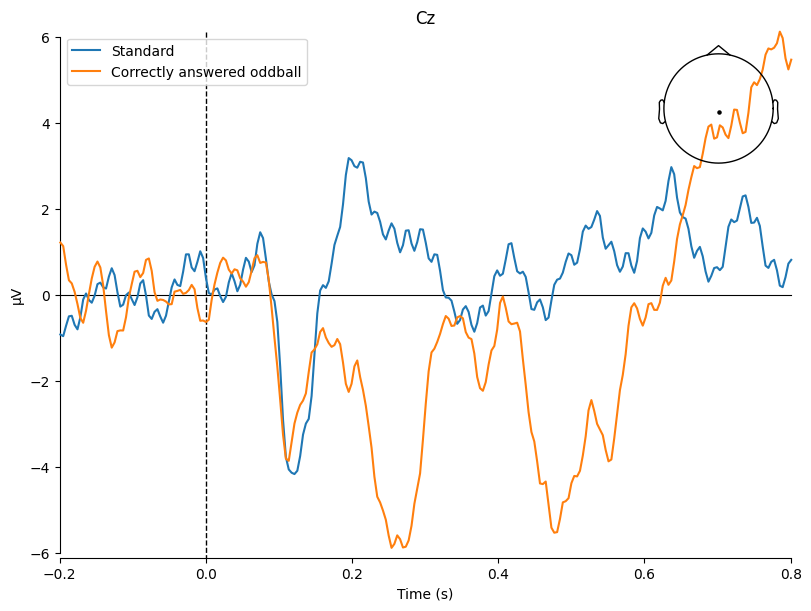

[<Figure size 800x600 with 2 Axes>]

In [32]:
## Averaging the EEG accross all the standard sound epochs

evoked_standard = epochs["standard"].average()

## Averaging the EEG accross correctly answered oddball epochs
evoked_oddball = epochs["oddball_with_reponse"].average()

## Plot both average responses at channel Cz
mne.viz.plot_compare_evokeds(
    {
        "Standard": evoked_standard,
        "Correctly answered oddball": evoked_oddball
    },
    picks="Cz"
)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 8449 samples (33.004 s)

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Used Annotations descriptions: ['oddball_with_reponse', 'standard']
Not setting metadata
634 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 634 events and 257 original time points ...
1 bad epochs dropped
Standard epochs: 521
Oddball epochs: 112

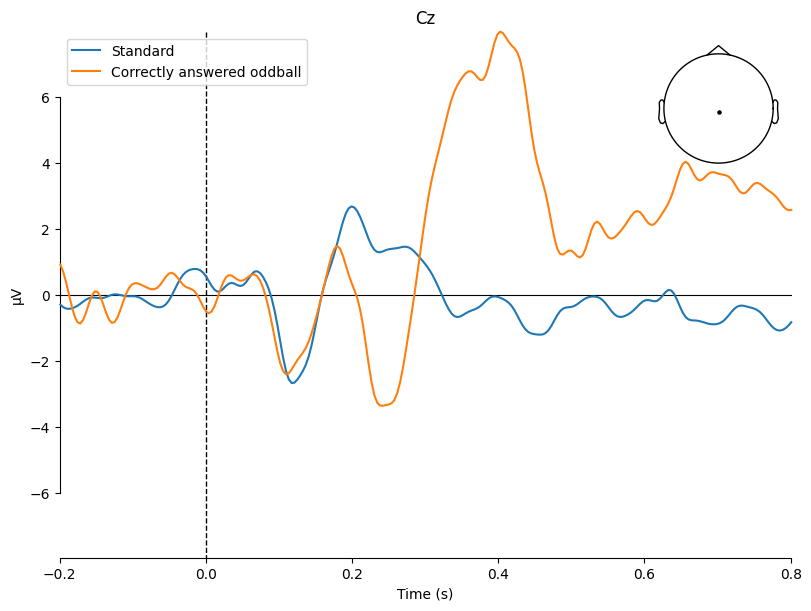

[<Figure size 800x600 with 2 Axes>]

In [37]:
## Make a copy so the original raw recording stays unchanged
raw_filtered = raw.copy()

## Reduce very slow drift and faster noise
raw_filtered.filter(l_freq=0.1, h_freq=30.0)

## measuring every electrode against the average of all electrodes
raw_filtered.set_eeg_reference("average", projection=False)

## Find the standard and correctly answered oddball events again
events_filtered, event_ids_filtered = mne.events_from_annotations(
    raw_filtered,
    event_id=event_map
)

## Cut a -0.2 to 0.8 second EEG window around each event
## The pre-sound period is used as the baseline
epochs_filtered = mne.Epochs(
    raw_filtered,
    events_filtered,
    event_id=event_ids_filtered,
    tmin=-0.2,
    tmax=0.8,
    baseline=(-0.2, 0),
    preload=True
)

## Show how many usable windows remain for each sound
print("Standard epochs:", len(epochs_filtered["standard"]))
print("Oddball epochs:", len(epochs_filtered["oddball_with_reponse"]))

## Average the windows separately for each sound type
evoked_standard_filtered = epochs_filtered["standard"].average()
evoked_oddball_filtered = epochs_filtered["oddball_with_reponse"].average()

## Compare the average responses at Cz
mne.viz.plot_compare_evokeds(
    {
        "Standard": evoked_standard_filtered,
        "Correctly answered oddball": evoked_oddball_filtered
    },
    picks="Cz"
)



In [38]:
## Show the shape of the standard average
print(evoked_standard_filtered.data.shape)

## Show how many sensor names are stored in it
print(len(evoked_standard_filtered.ch_names))

(64, 257)
64


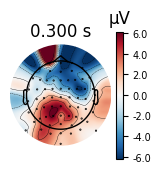

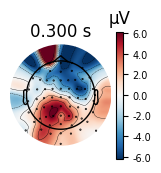

In [39]:
## Calculate oddball average minus standard average
difference_filtered = mne.combine_evoked(
    [evoked_oddball_filtered, evoked_standard_filtered],
    weights=[1, -1]
)

## Show the difference across all scalp sensors, 0.3 seconds after the sound
difference_filtered.plot_topomap(times=[0.3], ch_type="eeg")

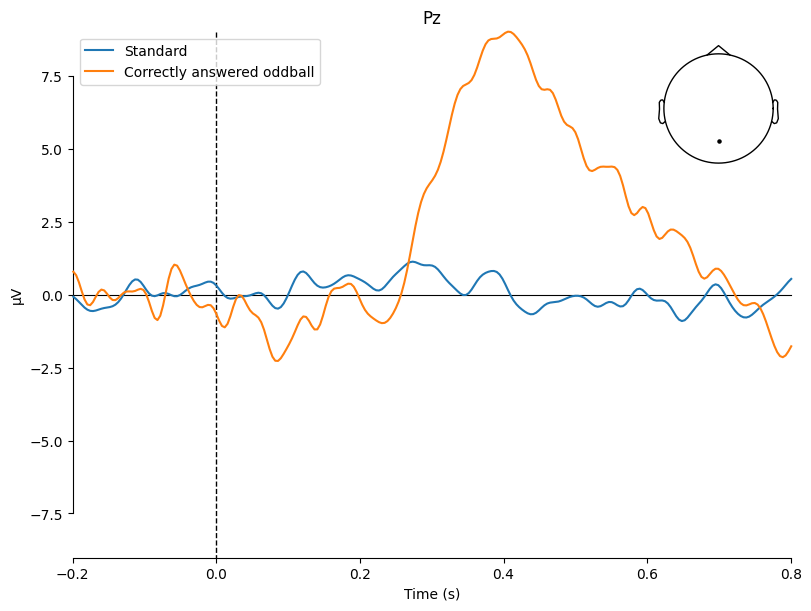

[<Figure size 800x600 with 2 Axes>]

In [40]:
## Compare the filtered averages at the parietal sensor Pz
mne.viz.plot_compare_evokeds(
    {
        "Standard": evoked_standard_filtered,
        "Correctly answered oddball": evoked_oddball_filtered
    },
    picks="Pz"
)